# Model Comparison — Random Forest vs XGBoost

## Part C — Comparison of Model 1 and Model 2

This notebook presents a comparative evaluation of the two predictive models developed for the STADIOalot Return Prediction project:

* **Model 1 — Random Forest Classifier**
* **Model 2 — XGBoost Classifier**

Both models are evaluated using the same feature-engineered dataset and the same **stratified 80/20 train-test split** with `random_state=42`. Using identical test observations ensures that the performance comparison is fair and reproducible.

The comparison determines which model provides stronger predictive performance for identifying whether an order will be returned.

---

## Performance Metrics

The following classification performance metrics are calculated and compared for both models:

* **Accuracy** — measures the overall proportion of correctly classified observations.
* **Precision** — measures the proportion of observations predicted as returned that were actually returned.
* **Recall** — measures the proportion of actual returned orders that were correctly identified.
* **F1-Score** — provides a balance between precision and recall.
* **ROC-AUC** — measures the model's ability to distinguish between returned and non-returned orders across different classification thresholds.

Confusion matrices are also examined to identify the types of classification errors made by each model.

---

## Statistical Evaluation

Statistical methods are included to determine whether observed differences in model performance are likely to represent meaningful differences rather than variation caused by the test sample.

### 1. Bootstrap 95% Confidence Intervals

Bootstrap resampling is used to estimate the uncertainty associated with the observed performance metrics.

A total of **1,000 bootstrap samples** are generated from the test set. For each bootstrap sample, the performance metrics are recalculated. The **2.5th and 97.5th percentiles** of the bootstrap distribution are used to construct the **95% confidence interval**.

Bootstrap confidence intervals are calculated for:

* Accuracy
* Precision
* Recall
* F1-Score
* ROC-AUC

In addition, a **paired bootstrap comparison** is performed using the same resampled test observations for both models. This estimates the 95% confidence interval for the difference between Model 2 and Model 1:

**Model 2 − Model 1**

If the confidence interval for the difference does not include zero, this provides evidence that the models differ in performance for that metric.

---

### 2. McNemar's Test

**McNemar's test** is used to compare the paired classification errors produced by the two models.

The test is appropriate because both Random Forest and XGBoost make predictions on the **same test observations**. Rather than comparing the models as if they were evaluated on independent samples, McNemar's test examines whether the models have significantly different patterns of classification errors.

The paired outcomes are classified into four categories:

1. Both models correctly classify the observation.
2. Model 1 is correct and Model 2 is incorrect.
3. Model 1 is incorrect and Model 2 is correct.
4. Both models are incorrect.

The significance level is set to:

`alpha = 0.05`

The hypotheses are:

* **H₀:** There is no statistically significant difference between the paired classification error patterns of the two models.
* **H₁:** There is a statistically significant difference between the paired classification error patterns of the two models.

The decision rule is:

* **p < 0.05** → Reject H₀; there is a statistically significant difference in the paired classification errors.
* **p ≥ 0.05** → Fail to reject H₀; there is insufficient evidence of a statistically significant difference in the paired classification errors.

---

## Model Comparison

The final comparison considers both predictive performance and statistical evidence.

The model comparison includes:

* Side-by-side performance metrics for Random Forest and XGBoost.
* The difference between the two models for each performance metric.
* Paired bootstrap 95% confidence intervals for the metric differences.
* McNemar's test results.
* Confusion matrices for both models.
* ROC curves for visual comparison of classification performance.

The best-performing model is determined based on the overall combination of **Accuracy, Precision, Recall, F1-Score, and ROC-AUC**, while the statistical tests are used to assess the reliability of the observed differences.

---

## Reproducibility

The comparison uses:

* **Stratified train-test split:** 80/20
* **Random state:** `42`
* **Bootstrap samples:** `1,000`
* **Confidence level:** `95%`
* **Significance level:** `α = 0.05`

Using the same random state and evaluation observations ensures that the results can be reproduced when the notebook is executed again using the same dataset and saved model pipelines.

---

## Expected Outputs

The notebook produces the following result files in:

`STADIOalot-Return-Prediction/experimental_results/`

* `model_comparison_metrics.csv`
* `model_comparison_bootstrap_confidence_intervals.csv`
* `model_metric_differences.csv`
* `mcnemar_test.csv`

These files provide the numerical evidence required for the **Comparison of Model 1 and Model 2** section of Part C.


In [2]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4f}".format)

# ============================================================
# PROJECT ROOT
# ============================================================

ROOT = Path.cwd()

while ROOT != ROOT.parent and not (ROOT / "data").exists():
    ROOT = ROOT.parent

ROOT = ROOT.resolve()

# ============================================================
# PATHS
# ============================================================

DATA_PATH = (
    ROOT
    / "data"
    / "processed"
    / "returns_features.csv"
)

MODEL1_PATH = (
    ROOT
    / "models"
    / "model1_random_forest.joblib"
)

MODEL2_PATH = (
    ROOT
    / "models"
    / "model2_xgboost.joblib"
)

RESULTS_DIR = (
    ROOT
    / "experimental_results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_COMPARISON_PATH = (
    RESULTS_DIR
    / "model_comparison_metrics.csv"
)

BOOTSTRAP_COMPARISON_PATH = (
    RESULTS_DIR
    / "model_comparison_bootstrap_confidence_intervals.csv"
)

METRIC_DIFFERENCES_PATH = (
    RESULTS_DIR
    / "model_metric_differences.csv"
)

MCNEMAR_PATH = (
    RESULTS_DIR
    / "mcnemar_test.csv"
)

# ============================================================
# COMPLETE OUTPUT PATH TABLE
# ============================================================

comparison_output_paths = pd.DataFrame({
    "Output": [
        "Model Comparison Metrics",
        "Model Comparison Bootstrap Confidence Intervals",
        "Model Metric Differences",
        "McNemar Statistical Test"
    ],
    "File Name": [
        MODEL_COMPARISON_PATH.name,
        BOOTSTRAP_COMPARISON_PATH.name,
        METRIC_DIFFERENCES_PATH.name,
        MCNEMAR_PATH.name
    ],
    "Full Absolute Path": [
        str(MODEL_COMPARISON_PATH.resolve()),
        str(BOOTSTRAP_COMPARISON_PATH.resolve()),
        str(METRIC_DIFFERENCES_PATH.resolve()),
        str(MCNEMAR_PATH.resolve())
    ]
})

# ------------------------------------------------------------
# Prevent pandas from truncating the full file paths
# ------------------------------------------------------------

pd.set_option(
    "display.max_colwidth",
    None
)

pd.set_option(
    "display.width",
    300
)

display(
    comparison_output_paths
)

,Output,File Name,Full Absolute Path
0,Model Comparison Metrics,model_comparison_metrics.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model_comparison_metrics.csv
1,Model Comparison Bootstrap Confidence Intervals,model_comparison_bootstrap_confidence_intervals.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model_comparison_bootstrap_confidence_intervals.csv
2,Model Metric Differences,model_metric_differences.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model_metric_differences.csv
3,McNemar Statistical Test,mcnemar_test.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\mcnemar_test.csv


In [3]:
# ============================================================
# 2. LOAD DATASET AND CREATE COMMON TEST SET
# ============================================================

TARGET_COLUMN = "Return_Status"

df = pd.read_csv(
    DATA_PATH
)

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Target column '{TARGET_COLUMN}' was not found."
    )

X = df.drop(
    columns=[TARGET_COLUMN]
)

y = df[TARGET_COLUMN].astype(int)

# ============================================================
# IDENTICAL SPLIT FOR BOTH MODELS
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

comparison_dataset_summary = pd.DataFrame({
    "Item": [
        "Dataset",
        "Total Rows",
        "Training Rows",
        "Testing Rows",
        "Train/Test Split",
        "Random State",
        "Stratified"
    ],
    "Value": [
        DATA_PATH.name,
        len(X),
        len(X_train),
        len(X_test),
        "80% / 20%",
        42,
        "Yes"
    ]
})

display(
    comparison_dataset_summary
)

,Item,Value
0,Dataset,returns_features.csv
1,Total Rows,10000
2,Training Rows,8000
3,Testing Rows,2000
4,Train/Test Split,80% / 20%
5,Random State,42
6,Stratified,Yes


In [4]:
# ============================================================
# 3. LOAD BOTH TRAINED MODEL PIPELINES
# ============================================================

if not MODEL1_PATH.exists():
    raise FileNotFoundError(
        f"Model 1 not found:\n{MODEL1_PATH}"
    )

if not MODEL2_PATH.exists():
    raise FileNotFoundError(
        f"Model 2 not found:\n{MODEL2_PATH}"
    )

model1 = joblib.load(
    MODEL1_PATH
)

model2 = joblib.load(
    MODEL2_PATH
)

model_load_summary = pd.DataFrame({
    "Model": [
        "Model 1",
        "Model 2"
    ],
    "Algorithm": [
        "Random Forest",
        "XGBoost"
    ],
    "Full Model Path": [
        str(MODEL1_PATH.resolve()),
        str(MODEL2_PATH.resolve())
    ],
    "Loaded": [
        model1 is not None,
        model2 is not None
    ]
})

display(
    model_load_summary
)

,Model,Algorithm,Full Model Path,Loaded
0,Model 1,Random Forest,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\models\model1_random_forest.joblib,True
1,Model 2,XGBoost,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\models\model2_xgboost.joblib,True


In [5]:
# ============================================================
# 4. GENERATE PREDICTIONS FOR BOTH MODELS
# ============================================================

# Both models are evaluated against exactly the same y_test values.

y_pred_model1 = model1.predict(
    X_test
)

y_probability_model1 = (
    model1
    .predict_proba(X_test)[:, 1]
)

y_pred_model2 = model2.predict(
    X_test
)

y_probability_model2 = (
    model2
    .predict_proba(X_test)[:, 1]
)

# ============================================================
# PREDICTION VALIDATION
# ============================================================

prediction_validation = pd.DataFrame({
    "Prediction": [
        "Model 1 Class",
        "Model 1 Probability",
        "Model 2 Class",
        "Model 2 Probability"
    ],
    "Rows": [
        len(y_pred_model1),
        len(y_probability_model1),
        len(y_pred_model2),
        len(y_probability_model2)
    ],
    "Matches Test Set": [
        len(y_pred_model1) == len(y_test),
        len(y_probability_model1) == len(y_test),
        len(y_pred_model2) == len(y_test),
        len(y_probability_model2) == len(y_test)
    ]
})

display(
    prediction_validation
)

,Prediction,Rows,Matches Test Set
0,Model 1 Class,2000,True
1,Model 1 Probability,2000,True
2,Model 2 Class,2000,True
3,Model 2 Probability,2000,True


In [6]:
# ============================================================
# 5. SIDE-BY-SIDE PERFORMANCE COMPARISON
# ============================================================

def calculate_metrics(
    y_true,
    y_pred,
    y_probability
):

    return {
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "F1-Score": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true,
            y_probability
        )
    }


# ============================================================
# CALCULATE MODEL 1 METRICS
# ============================================================

model1_metrics = calculate_metrics(
    y_test,
    y_pred_model1,
    y_probability_model1
)


# ============================================================
# CALCULATE MODEL 2 METRICS
# ============================================================

model2_metrics = calculate_metrics(
    y_test,
    y_pred_model2,
    y_probability_model2
)


# ============================================================
# COMPARISON TABLE
# ============================================================

comparison_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "Model 1 — Random Forest": [
        model1_metrics["Accuracy"],
        model1_metrics["Precision"],
        model1_metrics["Recall"],
        model1_metrics["F1-Score"],
        model1_metrics["ROC-AUC"]
    ],

    "Model 2 — XGBoost": [
        model2_metrics["Accuracy"],
        model2_metrics["Precision"],
        model2_metrics["Recall"],
        model2_metrics["F1-Score"],
        model2_metrics["ROC-AUC"]
    ]
})


# ============================================================
# CALCULATE DIFFERENCE
# ============================================================

comparison_table["Difference"] = (
    comparison_table["Model 2 — XGBoost"]
    -
    comparison_table["Model 1 — Random Forest"]
)


# ============================================================
# DETERMINE BETTER MODEL
# ============================================================

comparison_table["Better Model"] = np.where(
    comparison_table["Difference"] > 0,
    "Model 2 — XGBoost",
    np.where(
        comparison_table["Difference"] < 0,
        "Model 1 — Random Forest",
        "Tie"
    )
)


# ============================================================
# 6. SAVE MODEL COMPARISON METRICS
# ============================================================

comparison_table.to_csv(
    MODEL_COMPARISON_PATH,
    index=False
)


display(
    comparison_table
)

# ============================================================
# DISPLAY SAVED FILE PATH IN A TABLE
# ============================================================

saved_file_table = pd.DataFrame({
    "File": [
        "Model Comparison Metrics"
    ],
    
    "Output Path": [
        str(MODEL_COMPARISON_PATH.resolve())
    ]
})

display(saved_file_table)

,Metric,Model 1 — Random Forest,Model 2 — XGBoost,Difference,Better Model
0,Accuracy,0.5000,0.5025,0.0025,Model 2 — XGBoost
1,Precision,0.5048,0.5071,0.0023,Model 2 — XGBoost
2,Recall,0.5198,0.5327,0.0129,Model 2 — XGBoost
3,F1-Score,0.5122,0.5196,0.0074,Model 2 — XGBoost
4,ROC-AUC,0.4925,0.4960,0.0035,Model 2 — XGBoost


,File,Output Path
0,Model Comparison Metrics,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model_comparison_metrics.csv


In [7]:
# ============================================================
# 7. CONFUSION MATRIX COMPARISON
# ============================================================

cm1 = confusion_matrix(
    y_test,
    y_pred_model1
)

cm2 = confusion_matrix(
    y_test,
    y_pred_model2
)

tn1, fp1, fn1, tp1 = cm1.ravel()
tn2, fp2, fn2, tp2 = cm2.ravel()

confusion_comparison = pd.DataFrame({
    "Measure": [
        "True Negatives (TN)",
        "False Positives (FP)",
        "False Negatives (FN)",
        "True Positives (TP)"
    ],

    "Model 1 — Random Forest": [
        tn1,
        fp1,
        fn1,
        tp1
    ],

    "Model 2 — XGBoost": [
        tn2,
        fp2,
        fn2,
        tp2
    ],

    "Difference": [
        tn2 - tn1,
        fp2 - fp1,
        fn2 - fn1,
        tp2 - tp1
    ]
})

display(
    confusion_comparison
)

,Measure,Model 1 — Random Forest,Model 2 — XGBoost,Difference
0,True Negatives (TN),475,467,-8
1,False Positives (FP),515,523,8
2,False Negatives (FN),485,472,-13
3,True Positives (TP),525,538,13


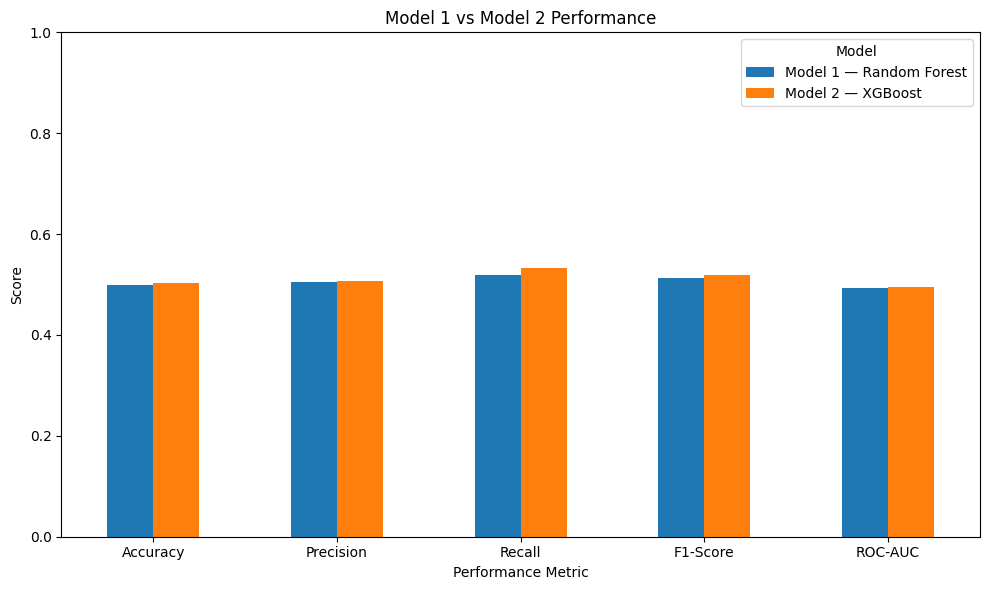

In [8]:
# ============================================================
# 8. PERFORMANCE METRIC COMPARISON CHART
# ============================================================

plot_table = comparison_table.set_index(
    "Metric"
)[
    [
        "Model 1 — Random Forest",
        "Model 2 — XGBoost"
    ]
]

ax = plot_table.plot(
    kind="bar",
    figsize=(10, 6)
)
ax.set_title("Model 1 vs Model 2 Performance")
ax.set_xlabel("Performance Metric")
ax.set_ylabel("Score")
ax.set_ylim(0,1)

plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# 9. MODEL METRIC DIFFERENCES
# ============================================================

metric_difference_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "Model 1 — Random Forest": [
        model1_metrics["Accuracy"],
        model1_metrics["Precision"],
        model1_metrics["Recall"],
        model1_metrics["F1-Score"],
        model1_metrics["ROC-AUC"]
    ],

    "Model 2 — XGBoost": [
        model2_metrics["Accuracy"],
        model2_metrics["Precision"],
        model2_metrics["Recall"],
        model2_metrics["F1-Score"],
        model2_metrics["ROC-AUC"]
    ]
})

# ============================================================
# ABSOLUTE DIFFERENCE
# ============================================================

metric_difference_table[
    "Absolute Difference"
] = (
    metric_difference_table[
        "Model 2 — XGBoost"
    ]
    -
    metric_difference_table[
        "Model 1 — Random Forest"
    ]
).abs()

# ============================================================
# PERCENTAGE DIFFERENCE
# ============================================================

metric_difference_table[
    "Percentage Difference (%)"
] = np.where(
    metric_difference_table[
        "Model 1 — Random Forest"
    ] != 0,

    (
        (
            metric_difference_table[
                "Model 2 — XGBoost"
            ]
            -
            metric_difference_table[
                "Model 1 — Random Forest"
            ]
        )
        /
        metric_difference_table[
            "Model 1 — Random Forest"
        ]
        * 100
    ),

    np.nan
)

# ============================================================
# DISPLAY
# ============================================================

display(
    metric_difference_table
)

# ============================================================
# SAVE
# ============================================================

metric_difference_table.to_csv(
    METRIC_DIFFERENCES_PATH,
    index=False
)

# ============================================================
# DISPLAY SAVED FILE PATH
# ============================================================

saved_file_table = pd.DataFrame({
    "File": [
        "Metric Differences"
    ],

    "Output Path": [
        str(METRIC_DIFFERENCES_PATH.resolve())
    ]
})

display(
    saved_file_table
)

,Metric,Model 1 — Random Forest,Model 2 — XGBoost,Absolute Difference,Percentage Difference (%)
0,Accuracy,0.5000,0.5025,0.0025,0.5000
1,Precision,0.5048,0.5071,0.0023,0.4479
2,Recall,0.5198,0.5327,0.0129,2.4762
3,F1-Score,0.5122,0.5196,0.0074,1.4371
4,ROC-AUC,0.4925,0.4960,0.0035,0.7005


,File,Output Path
0,Metric Differences,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model_metric_differences.csv


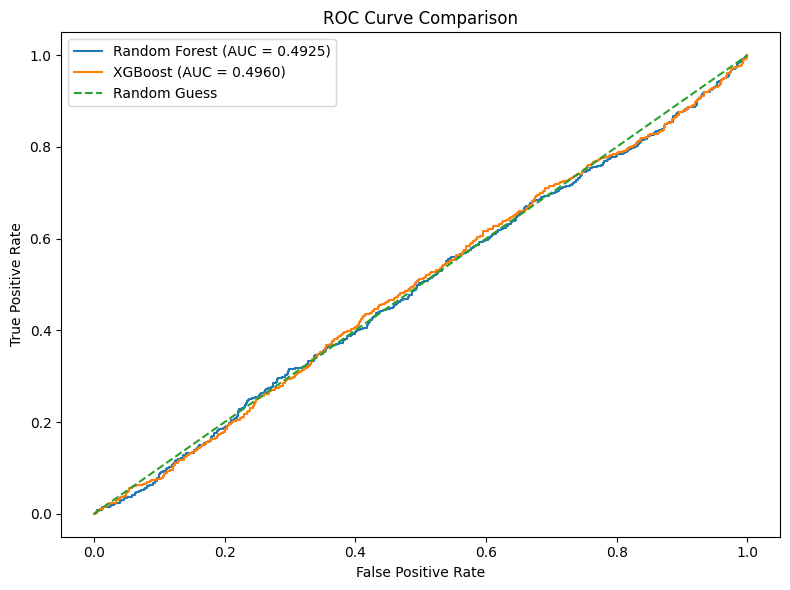

In [10]:
# ============================================================
# 10. ROC CURVE COMPARISON
# ============================================================

fpr1, tpr1, _ = roc_curve(
    y_test,
    y_probability_model1
)

fpr2, tpr2, _ = roc_curve(
    y_test,
    y_probability_model2
)

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    fpr1,
    tpr1,
    label=(
        f"Random Forest "
        f"(AUC = {model1_metrics['ROC-AUC']:.4f})"
    )
)

plt.plot(
    fpr2,
    tpr2,
    label=(
        f"XGBoost "
        f"(AUC = {model2_metrics['ROC-AUC']:.4f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.title(
    "ROC Curve Comparison"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()

plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# 11. BOOTSTRAP 95% CONFIDENCE INTERVALS AND PAIRED BOOTSTRAP COMPARISON
# ============================================================

rng = np.random.default_rng(42)

N_BOOTSTRAPS = 1000
n_test = len(y_test)

bootstrap_rows = []

# ============================================================
# INDIVIDUAL MODEL BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

for model_name, y_pred, y_probability in [
    (
        "Model 1 — Random Forest",
        y_pred_model1,
        y_probability_model1
    ),
    (
        "Model 2 — XGBoost",
        y_pred_model2,
        y_probability_model2
    )
]:

    observed = calculate_metrics(
        y_test,
        y_pred,
        y_probability
    )

    bootstrap_storage = {
        "Accuracy": [],
        "Precision": [],
        "Recall": [],
        "F1-Score": [],
        "ROC-AUC": []
    }

    for _ in range(N_BOOTSTRAPS):

        indices = rng.integers(
            0,
            n_test,
            n_test
        )

        y_true_bootstrap = y_test.iloc[
            indices
        ]

        y_pred_bootstrap = np.asarray(
            y_pred
        )[indices]

        y_probability_bootstrap = np.asarray(
            y_probability
        )[indices]

        bootstrap_storage["Accuracy"].append(
            accuracy_score(
                y_true_bootstrap,
                y_pred_bootstrap
            )
        )

        bootstrap_storage["Precision"].append(
            precision_score(
                y_true_bootstrap,
                y_pred_bootstrap,
                zero_division=0
            )
        )

        bootstrap_storage["Recall"].append(
            recall_score(
                y_true_bootstrap,
                y_pred_bootstrap,
                zero_division=0
            )
        )

        bootstrap_storage["F1-Score"].append(
            f1_score(
                y_true_bootstrap,
                y_pred_bootstrap,
                zero_division=0
            )
        )

        if len(
            np.unique(y_true_bootstrap)
        ) == 2:

            bootstrap_storage["ROC-AUC"].append(
                roc_auc_score(
                    y_true_bootstrap,
                    y_probability_bootstrap
                )
            )

    for metric, values in bootstrap_storage.items():

        bootstrap_rows.append({
            "Analysis": "Individual Model",
            "Model": model_name,
            "Metric": metric,
            "Observed Score": observed[metric],
            "95% CI Lower": np.percentile(
                values,
                2.5
            ),
            "95% CI Upper": np.percentile(
                values,
                97.5
            ),
            "Bootstrap Samples": len(values),
            "CI Includes Zero": np.nan,
            "Interpretation": np.nan
        })


# ============================================================
# PAIRED BOOTSTRAP COMPARISON
# ============================================================

# The SAME bootstrap indices are used for both models.
# Difference = Model 2 metric - Model 1 metric.

rng = np.random.default_rng(42)

paired_bootstrap_rows = []

# ============================================================
# LOOP THROUGH METRICS
# ============================================================

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]:

    bootstrap_differences = []

    # --------------------------------------------------------
    # BOOTSTRAP RESAMPLING
    # --------------------------------------------------------

    for _ in range(N_BOOTSTRAPS):

        indices = rng.integers(
            0,
            n_test,
            n_test
        )

        y_true_bootstrap = y_test.iloc[
            indices
        ]

        pred1_bootstrap = np.asarray(
            y_pred_model1
        )[indices]

        pred2_bootstrap = np.asarray(
            y_pred_model2
        )[indices]

        prob1_bootstrap = np.asarray(
            y_probability_model1
        )[indices]

        prob2_bootstrap = np.asarray(
            y_probability_model2
        )[indices]

        # ----------------------------------------------------
        # CALCULATE METRIC
        # ----------------------------------------------------

        if metric == "Accuracy":

            score1 = accuracy_score(
                y_true_bootstrap,
                pred1_bootstrap
            )

            score2 = accuracy_score(
                y_true_bootstrap,
                pred2_bootstrap
            )

        elif metric == "Precision":

            score1 = precision_score(
                y_true_bootstrap,
                pred1_bootstrap,
                zero_division=0
            )

            score2 = precision_score(
                y_true_bootstrap,
                pred2_bootstrap,
                zero_division=0
            )

        elif metric == "Recall":

            score1 = recall_score(
                y_true_bootstrap,
                pred1_bootstrap,
                zero_division=0
            )

            score2 = recall_score(
                y_true_bootstrap,
                pred2_bootstrap,
                zero_division=0
            )

        elif metric == "F1-Score":

            score1 = f1_score(
                y_true_bootstrap,
                pred1_bootstrap,
                zero_division=0
            )

            score2 = f1_score(
                y_true_bootstrap,
                pred2_bootstrap,
                zero_division=0
            )

        elif metric == "ROC-AUC":

            # Skip bootstrap sample if only one class exists.

            if len(
                np.unique(y_true_bootstrap)
            ) < 2:

                continue

            score1 = roc_auc_score(
                y_true_bootstrap,
                prob1_bootstrap
            )

            score2 = roc_auc_score(
                y_true_bootstrap,
                prob2_bootstrap
            )

        # ----------------------------------------------------
        # STORE MODEL 2 - MODEL 1 DIFFERENCE
        # ----------------------------------------------------

        bootstrap_differences.append(
            score2 - score1
        )

    # ========================================================
    # OBSERVED DIFFERENCE
    # ========================================================

    observed_difference = (
        model2_metrics[metric]
        -
        model1_metrics[metric]
    )

    # ========================================================
    # CONFIDENCE INTERVAL
    # ========================================================

    lower_ci = np.percentile(
        bootstrap_differences,
        2.5
    )

    upper_ci = np.percentile(
        bootstrap_differences,
        97.5
    )

    # ========================================================
    # INTERPRETATION
    # ========================================================

    if lower_ci > 0:

        interpretation = (
            "Evidence that Model 2 performs better"
        )

    elif upper_ci < 0:

        interpretation = (
            "Evidence that Model 1 performs better"
        )

    else:

        interpretation = (
            "Confidence interval includes zero"
        )

    # ========================================================
    # STORE RESULT
    # ========================================================

    paired_bootstrap_rows.append({
        "Analysis": "Paired Model Comparison",
        "Model": "Model 2 — XGBoost vs Model 1 — Random Forest",
        "Metric": metric,
        "Observed Score": observed_difference,
        "95% CI Lower": lower_ci,
        "95% CI Upper": upper_ci,
        "Bootstrap Samples": len(
            bootstrap_differences
        ),
        "CI Includes Zero": (
            lower_ci <= 0 <= upper_ci
        ),
        "Interpretation": interpretation
    })


# ============================================================
# COMBINE BOTH BOOTSTRAP RESULTS
# ============================================================

bootstrap_comparison = pd.DataFrame(
    bootstrap_rows + paired_bootstrap_rows
)


# ============================================================
# DISPLAY COMBINED BOOTSTRAP TABLE
# ============================================================

display(
    bootstrap_comparison
)


# ============================================================
# SAVE COMBINED BOOTSTRAP RESULTS
# ============================================================

bootstrap_comparison.to_csv(
    BOOTSTRAP_COMPARISON_PATH,
    index=False
)


# ============================================================
# DISPLAY SAVED FILE PATH IN A TABLE
# ============================================================

saved_file_table = pd.DataFrame({
    "File": [
        "Bootstrap Confidence Intervals and Paired Comparison"
    ],

    "Output Path": [
        str(
            BOOTSTRAP_COMPARISON_PATH.resolve()
        )
    ]
})


display(
    saved_file_table
)

,Analysis,Model,Metric,Observed Score,95% CI Lower,95% CI Upper,Bootstrap Samples,CI Includes Zero,Interpretation
0,Individual Model,Model 1 — Random Forest,Accuracy,0.5000,0.4795,0.5220,1000,NaN,NaN
1,Individual Model,Model 1 — Random Forest,Precision,0.5048,0.4748,0.5376,1000,NaN,NaN
2,Individual Model,Model 1 — Random Forest,Recall,0.5198,0.4884,0.5526,1000,NaN,NaN
3,Individual Model,Model 1 — Random Forest,F1-Score,0.5122,0.4846,0.5391,1000,NaN,NaN
4,Individual Model,Model 1 — Random Forest,ROC-AUC,0.4925,0.4677,0.5171,1000,NaN,NaN
5,Individual Model,Model 2 — XGBoost,Accuracy,0.5025,0.4810,0.5240,1000,NaN,NaN
6,Individual Model,Model 2 — XGBoost,Precision,0.5071,0.4756,0.5362,1000,NaN,NaN
7,Individual Model,Model 2 — XGBoost,Recall,0.5327,0.5015,0.5628,1000,NaN,NaN
8,Individual Model,Model 2 — XGBoost,F1-Score,0.5196,0.4919,0.5440,1000,NaN,NaN
9,Individual Model,Model 2 — XGBoost,ROC-AUC,0.4960,0.4709,0.5212,1000,NaN,NaN


,File,Output Path
0,Bootstrap Confidence Intervals and Paired Comparison,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model_comparison_bootstrap_confidence_intervals.csv


In [12]:
# ============================================================
# 12. McNEMAR'S TEST
# ============================================================

# McNemar's test compares paired classification results.
# Both models predict the same test observations, making this an appropriate statistical test for comparing 
# their error patterns.

model1_correct = (
    np.asarray(y_pred_model1)
    ==
    np.asarray(y_test)
)

model2_correct = (
    np.asarray(y_pred_model2)
    ==
    np.asarray(y_test)
)

# ============================================================
# PAIRED COUNTS
# ============================================================

both_correct = int(
    np.sum(
        model1_correct
        &
        model2_correct
    )
)

model1_correct_model2_wrong = int(
    np.sum(
        model1_correct
        &
        ~model2_correct
    )
)

model1_wrong_model2_correct = int(
    np.sum(
        ~model1_correct
        &
        model2_correct
    )
)

both_wrong = int(
    np.sum(
        ~model1_correct
        &
        ~model2_correct
    )
)

# ============================================================
# CONTINGENCY TABLE
# ============================================================

mcnemar_contingency = np.array([
    [
        both_correct,
        model1_correct_model2_wrong
    ],
    [
        model1_wrong_model2_correct,
        both_wrong
    ]
])

mcnemar_table = pd.DataFrame(
    mcnemar_contingency,
    index=[
        "Model 1 Correct",
        "Model 1 Incorrect"
    ],
    columns=[
        "Model 2 Correct",
        "Model 2 Incorrect"
    ]
)

display(
    mcnemar_table
)

# ============================================================
# McNEMAR TEST
# ============================================================

mcnemar_result = mcnemar(
    mcnemar_contingency,
    exact=False,
    correction=True
)

ALPHA = 0.05

# ============================================================
# DECISION
# ============================================================

if mcnemar_result.pvalue < ALPHA:

    decision = (
        "Reject H0 — statistically significant "
        "difference in paired classification errors"
    )

else:

    decision = (
        "Fail to reject H0 — no statistically "
        "significant difference in paired "
        "classification errors"
    )

# ============================================================
# RESULT TABLE
# ============================================================

mcnemar_results_table = pd.DataFrame({
    "Test": [
        "McNemar's Test"
    ],

    "Model 1 Correct / Model 2 Incorrect": [
        model1_correct_model2_wrong
    ],

    "Model 1 Incorrect / Model 2 Correct": [
        model1_wrong_model2_correct
    ],

    "Both Correct": [
        both_correct
    ],

    "Both Incorrect": [
        both_wrong
    ],

    "Test Statistic": [
        mcnemar_result.statistic
    ],

    "p-value": [
        mcnemar_result.pvalue
    ],

    "Alpha": [
        ALPHA
    ],

    "Decision": [
        decision
    ]
})

display(
    mcnemar_results_table
)

# ============================================================
# SAVE
# ============================================================

mcnemar_results_table.to_csv(
    MCNEMAR_PATH,
    index=False
)

# ============================================================
# DISPLAY SAVED FILE PATH IN A TABLE
# ============================================================

saved_file_table = pd.DataFrame({
    "File": [
        "McNemar's Test Results"
    ],

    "Output Path": [
        str(
            MCNEMAR_PATH.resolve()
        )
    ]
})

display(
    saved_file_table
)

,Model 2 Correct,Model 2 Incorrect
Model 1 Correct,760,240
Model 1 Incorrect,245,755


,Test,Model 1 Correct / Model 2 Incorrect,Model 1 Incorrect / Model 2 Correct,Both Correct,Both Incorrect,Test Statistic,p-value,Alpha,Decision
0,McNemar's Test,240,245,760,755,0.0330,0.8559,0.0500,Fail to reject H0 — no statistically significant difference in paired classification errors


,File,Output Path
0,McNemar's Test Results,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\mcnemar_test.csv


In [14]:
# ============================================================
# 13. OVERALL MODEL DECISION
# ============================================================

# F1-Score is used as the primary decision criterion
# because it balances precision and recall.
#
# ROC-AUC is used as an additional discrimination criterion.
#
# alpha = 0.05 is used as the statistical significance level
# for McNemar's Test.

alpha = 0.05


# ------------------------------------------------------------
# PRIMARY CRITERION — F1-SCORE
# ------------------------------------------------------------

if model1_metrics["F1-Score"] > model2_metrics["F1-Score"]:

    primary_winner = "Model 1 — Random Forest"

elif model2_metrics["F1-Score"] > model1_metrics["F1-Score"]:

    primary_winner = "Model 2 — XGBoost"

else:

    primary_winner = "Tie"


# ------------------------------------------------------------
# SECONDARY CRITERION — ROC-AUC
# ------------------------------------------------------------

if model1_metrics["ROC-AUC"] > model2_metrics["ROC-AUC"]:

    auc_winner = "Model 1 — Random Forest"

elif model2_metrics["ROC-AUC"] > model1_metrics["ROC-AUC"]:

    auc_winner = "Model 2 — XGBoost"

else:

    auc_winner = "Tie"


# ------------------------------------------------------------
# McNEMAR'S TEST RESULT
# ------------------------------------------------------------

if mcnemar_result.pvalue < alpha:

    mcnemar_conclusion = "Significant"

else:

    mcnemar_conclusion = "Not Significant"


# ------------------------------------------------------------
# OVERALL DECISION TABLE
# ------------------------------------------------------------

overall_decision = pd.DataFrame({

    "Decision Area": [
        "Primary Criterion",
        "Primary Winner",
        "Secondary Criterion",
        "ROC-AUC Winner",
        "Statistical Test",
        "Significance Level",
        "McNemar Result"
    ],

    "Result": [
        "F1-Score",
        primary_winner,
        "ROC-AUC",
        auc_winner,
        "McNemar's Test",
        "alpha = 0.05",
        mcnemar_conclusion
    ],

    "Reason": [
        "Balances precision and recall",
        "Highest F1-score",
        "Measures overall class discrimination",
        "Highest ROC-AUC",
        "Tests paired classification differences",
        "Standard significance threshold",
        "Determined from the p-value"
    ]
})


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

display(
    overall_decision
)

,Decision Area,Result,Reason
0,Primary Criterion,F1-Score,Balances precision and recall
1,Primary Winner,Model 2 — XGBoost,Highest F1-score
2,Secondary Criterion,ROC-AUC,Measures overall class discrimination
3,ROC-AUC Winner,Model 2 — XGBoost,Highest ROC-AUC
4,Statistical Test,McNemar's Test,Tests paired classification differences
5,Significance Level,alpha = 0.05,Standard significance threshold
6,McNemar Result,Not Significant,Determined from the p-value


In [15]:
# ============================================================
# 14. VERIFY ALL OUTPUT FILES
# ============================================================

expected_files = [
    ROOT
    / "experimental_results"
    / "model1_random_forest_metrics.csv",

    ROOT
    / "experimental_results"
    / "model1_bootstrap_confidence_intervals.csv",

    ROOT
    / "experimental_results"
    / "model2_xgboost_metrics.csv",

    ROOT
    / "experimental_results"
    / "model2_bootstrap_confidence_intervals.csv",

    ROOT
    / "experimental_results"
    / "model_comparison_metrics.csv",

    ROOT
    / "experimental_results"
    / "model_comparison_bootstrap_confidence_intervals.csv",

    ROOT
    / "experimental_results"
    / "model_metric_differences.csv",

    ROOT
    / "experimental_results"
    / "mcnemar_test.csv"
]

# ============================================================
# BUILD VERIFICATION TABLE
# ============================================================

verification_rows = []

for file_path in expected_files:

    verification_rows.append({
        "Required Output": file_path.name,
        "Full Path": str(
            file_path.resolve()
        ),
        "Exists": file_path.exists(),
        "Size (KB)": (
            round(
                file_path.stat().st_size / 1024,
                2
            )
            if file_path.exists()
            else 0
        )
    })

verification_table = pd.DataFrame(
    verification_rows
)

display(
    verification_table
)

# ============================================================
# FINAL CHECK
# ============================================================

all_files_exist = all(
    file_path.exists()
    for file_path in expected_files
)

if all_files_exist:

    print(
        "SUCCESS: All required Part C "
        "experimental result files exist."
    )

else:

    print(
        "WARNING: One or more required "
        "Part C result files are missing."
    )

,Required Output,Full Path,Exists,Size (KB)
0,model1_random_forest_metrics.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model1_random_forest_metrics.csv,True,0.1400
1,model1_bootstrap_confidence_intervals.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model1_bootstrap_confidence_intervals.csv,True,0.5800
2,model2_xgboost_metrics.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model2_xgboost_metrics.csv,True,0.1400
3,model2_bootstrap_confidence_intervals.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model2_bootstrap_confidence_intervals.csv,True,0.6100
4,model_comparison_metrics.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model_comparison_metrics.csv,True,0.4900
5,model_comparison_bootstrap_confidence_intervals.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model_comparison_bootstrap_confidence_intervals.csv,True,2.0800
6,model_metric_differences.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model_metric_differences.csv,True,0.5000
7,mcnemar_test.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\mcnemar_test.csv,True,0.3100


SUCCESS: All required Part C experimental result files exist.
